# Proyek Rekayasa Data Post UTS
## Implementasi Data Pipeline dan Data Warehouse


### Anggota Kelompok:

*   Adnan
*   Aston
*   Muhammad Ilkham Abdillah (24/537977/TK/59653)
*   Juan Christopher Reinaldo Sipayung (24/544528/TK/60526)
*   Natanael Sebastian Simanjuntak (24/542676/TK/60273)
*   Rafif Raihan Bahrul Alam (24/534432/TK/59237)
*   Rakan Hendian Ramadhan (24/540158/TK/59909)
*   Rian
---
Data Source:
*   presence_kapanewon_hourly.csv
*   od_home_visits_kapanewon_monthly.csv

---
**Alur pipeline** (lihat `PLAN.md`):

```
Extract (CSV) → staging.*_raw → Profiling → Transform → staging.*_clean
             → Build DW (dw.dim_*, dw.fact_*) → Quality Check → Analytics → Visualisasi
```

## 0. Setup & Konfigurasi Path

Notebook membaca data dari folder `data/` di **root repo** dan menulis database ke `db/mobility.duckdb`.
- **Lokal / WSL**: jalankan Jupyter dari dalam repo (atau subfolder mana pun). Root repo dicari otomatis.
- **Google Colab**: sel di bawah otomatis meng-*clone* repo GitHub, lalu memakai path yang sama.

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/IlkhamAbdillah/yogyakarta-mobility-analytics.git"

if IN_COLAB:
    colab_root = Path("/content/yogyakarta-mobility-analytics")
    if not colab_root.exists():
        !git clone -q {REPO_URL} {colab_root}
    %pip install -q -r {colab_root}/requirements.txt
    os.chdir(colab_root)


def find_repo_root(start: Path) -> Path:
    """Naik dari folder kerja sampai menemukan folder yang berisi data/ dan PLAN.md / .git."""
    for p in [start, *start.parents]:
        if (p / "data").is_dir() and ((p / ".git").exists() or (p / "PLAN.md").exists()):
            return p
    raise FileNotFoundError("Root repo tidak ditemukan. Jalankan notebook dari dalam folder repo.")


ROOT = find_repo_root(Path.cwd().resolve())
DATA_DIR = ROOT / "data"
DB_DIR = ROOT / "db"
DB_DIR.mkdir(exist_ok=True)
DB_PATH = DB_DIR / "mobility.duckdb"

PRESENCE_CSV = DATA_DIR / "presence_kapanewon_hourly.csv"
OD_CSV = DATA_DIR / "od_home_visits_kapanewon_monthly.csv"

print("ROOT     :", ROOT)
print("DATA_DIR :", DATA_DIR)
print("DB_PATH  :", DB_PATH)

ROOT     : /home/veevry/yogyakarta-mobility-analytics
DATA_DIR : /home/veevry/yogyakarta-mobility-analytics/data
DB_PATH  : /home/veevry/yogyakarta-mobility-analytics/db/mobility.duckdb


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb

pd.set_option("display.max_columns", 50)
con = duckdb.connect(str(DB_PATH))
con.execute("CREATE SCHEMA IF NOT EXISTS staging").fetchall()
con.execute("CREATE SCHEMA IF NOT EXISTS dw").fetchall()
print("DuckDB", duckdb.__version__, "terhubung ke", DB_PATH.name)

DuckDB 2.0.0 terhubung ke mobility.duckdb


---
## 1. Extract → Staging (Raw)

Data mentah dibaca **apa adanya** lalu disimpan ke schema `staging` sebelum di-*transform*, sehingga ada salinan raw di Data Warehouse yang bisa diaudit ulang.

Kolom kode wilayah dibaca sebagai **string** (`dtype=str`). Tanpa ini Pandas membaca `kab_code` seperti `34.01` sebagai *float*.

In [3]:
PRESENCE_DTYPES = {"kab_code": "string", "kapanewon_code": "string"}
OD_DTYPES = {"month": "string", "origin_kab_code": "string", "origin_code": "string",
             "dest_kab_code": "string", "dest_code": "string"}

df_presence = pd.read_csv(PRESENCE_CSV, dtype=PRESENCE_DTYPES)
df_od = pd.read_csv(OD_CSV, dtype=OD_DTYPES)

print("presence:", df_presence.shape, "| od:", df_od.shape)
display(df_presence.head())
display(df_od.head())

presence: (230418, 8) | od: (9894, 11)


,kab_code,kab_kota,kapanewon_code,kapanewon,date,hour,n_maids,n_pings
0,34.01,KULON PROGO,34.01.01,TEMON,2021-12-01,0,16,66
1,34.01,KULON PROGO,34.01.02,WATES,2021-12-01,0,58,101
2,34.01,KULON PROGO,34.01.03,PANJATAN,2021-12-01,0,11,32
3,34.01,KULON PROGO,34.01.04,GALUR,2021-12-01,0,9,50
4,34.01,KULON PROGO,34.01.05,LENDAH,2021-12-01,0,14,74


,month,origin_kab_code,origin_kab_kota,origin_code,origin_kapanewon,dest_kab_code,dest_kab_kota,dest_code,dest_kapanewon,n_maids,reduced_quality
0,2021-12,34.01,KULON PROGO,34.01.01,TEMON,34.01,KULON PROGO,34.01.01,TEMON,569,False
1,2021-12,34.01,KULON PROGO,34.01.01,TEMON,34.01,KULON PROGO,34.01.02,WATES,85,False
2,2021-12,34.01,KULON PROGO,34.01.01,TEMON,34.01,KULON PROGO,34.01.03,PANJATAN,42,False
3,2021-12,34.01,KULON PROGO,34.01.01,TEMON,34.01,KULON PROGO,34.01.04,GALUR,16,False
4,2021-12,34.01,KULON PROGO,34.01.01,TEMON,34.01,KULON PROGO,34.01.05,LENDAH,8,False


In [4]:
def load_to_duckdb(df: pd.DataFrame, table: str) -> int:
    """CREATE OR REPLACE tabel DuckDB dari DataFrame, kembalikan jumlah baris di tabel."""
    con.register("_tmp_df", df)
    con.execute(f"CREATE OR REPLACE TABLE {table} AS SELECT * FROM _tmp_df").fetchall()
    con.unregister("_tmp_df")
    return con.execute(f"SELECT COUNT(*) FROM {table}").fetchall()[0][0]


for df, table in [(df_presence, "staging.presence_raw"), (df_od, "staging.od_raw")]:
    n = load_to_duckdb(df, table)
    print(f"{table:<24} {n:>8,} baris  (CSV: {len(df):,})  {'OK' if n == len(df) else 'MISMATCH'}")

staging.presence_raw      230,418 baris  (CSV: 230,418)  OK
staging.od_raw              9,894 baris  (CSV: 9,894)  OK


---
## 2. Data Understanding & Profiling (Audit Data Awal)

Tahap ini memeriksa kondisi data mentah sebelum *cleaning* dan *transform*:
1. **Struktur, tipe data, missing values, & duplikat**
2. **Cakupan temporal & kelengkapan slot** (efek *privacy suppression* k = 5)
3. **Konsistensi wilayah & relasi kode–nama**
4. **Distribusi numerik & kualitas data** (`reduced_quality`)

> **Aturan agregasi (README dataset, Section 3).**
> - `n_pings` bersifat **aditif**, jadi boleh di-`SUM`.
> - `n_maids` adalah *distinct device count* dan **tidak aditif**. Satu device yang muncul di 2 jam/kapanewon dihitung 2 kali, jadi **jangan di-`SUM`** lintas jam, hari, atau wilayah. Gunakan `AVG` / `MEDIAN` per slot.
> - Baris yang tidak ada berarti **< 5 device** (disuppress), **bukan nol**.

### 2.1 Struktur, Tipe Data, Missing Values, & Duplikat

In [5]:
def audit_dataframe(df, name, key_cols):
    print(f"{name}")
    print(f"Shape          : {df.shape[0]:,} baris x {df.shape[1]} kolom")
    print(f"Null values    : {int(df.isnull().sum().sum())} (per kolom: {df.isnull().sum().to_dict()})")
    print(f"Exact dupes    : {int(df.duplicated().sum())}")
    print(f"Key dupes {key_cols}: {int(df.duplicated(subset=key_cols).sum())}")
    print("Dtypes:")
    print(df.dtypes.to_string())
    print()

audit_dataframe(df_presence, "presence_kapanewon_hourly", ["kapanewon_code", "date", "hour"])
audit_dataframe(df_od, "od_home_visits_kapanewon_monthly", ["month", "origin_code", "dest_code"])

presence_kapanewon_hourly
Shape          : 230,418 baris x 8 kolom
Null values    : 0 (per kolom: {'kab_code': 0, 'kab_kota': 0, 'kapanewon_code': 0, 'kapanewon': 0, 'date': 0, 'hour': 0, 'n_maids': 0, 'n_pings': 0})
Exact dupes    : 0
Key dupes ['kapanewon_code', 'date', 'hour']: 0
Dtypes:
kab_code          string
kab_kota             str
kapanewon_code    string
kapanewon            str
date                 str
hour               int64
n_maids            int64
n_pings            int64

od_home_visits_kapanewon_monthly
Shape          : 9,894 baris x 11 kolom
Null values    : 0 (per kolom: {'month': 0, 'origin_kab_code': 0, 'origin_kab_kota': 0, 'origin_code': 0, 'origin_kapanewon': 0, 'dest_kab_code': 0, 'dest_kab_kota': 0, 'dest_code': 0, 'dest_kapanewon': 0, 'n_maids': 0, 'reduced_quality': 0})
Exact dupes    : 0
Key dupes ['month', 'origin_code', 'dest_code']: 0
Dtypes:
month               string
origin_kab_code     string
origin_kab_kota        str
origin_code         string
origi

### 2.2 Cakupan Temporal & Kelengkapan Slot (Privacy Threshold)

`coverage_pct` = persentase slot (kapanewon × hari × jam) yang terpublikasi. Ukuran sampel dibandingkan lewat **rata-rata `n_maids` per slot** dan **`SUM(n_pings)`**, bukan `SUM(n_maids)`.

In [6]:
p_dates = pd.to_datetime(df_presence["date"])
N_KAPANEWON = df_presence["kapanewon_code"].nunique()

print("Rentang tanggal presence :", p_dates.min().date(), "s.d.", p_dates.max().date(), f"({p_dates.nunique()} hari)")
print("Jam unik presence        :", sorted(df_presence["hour"].unique().tolist()))
print("Jumlah kapanewon         :", N_KAPANEWON)
print("Bulan unik OD            :", sorted(df_od["month"].unique().tolist()))

monthly_presence = df_presence.assign(month=p_dates.dt.to_period("M").astype(str)).groupby("month").agg(
    days=("date", "nunique"),
    kapanewon=("kapanewon_code", "nunique"),
    actual_rows=("n_maids", "count"),
    avg_maids_per_slot=("n_maids", "mean"),
    median_maids_per_slot=("n_maids", "median"),
    total_pings=("n_pings", "sum"),
)
monthly_presence["expected_max_rows"] = monthly_presence["days"] * N_KAPANEWON * 24
monthly_presence["coverage_pct"] = (monthly_presence["actual_rows"] / monthly_presence["expected_max_rows"] * 100).round(2)
display(monthly_presence.round(2))

Rentang tanggal presence : 2021-12-01 s.d. 2022-04-30 (151 hari)
Jam unik presence        : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]
Jumlah kapanewon         : 78
Bulan unik OD            : ['2021-12', '2022-01', '2022-02', '2022-03', '2022-04']


,days,kapanewon,actual_rows,avg_maids_per_slot,median_maids_per_slot,total_pings,expected_max_rows,coverage_pct
month,,,,,,,,
2021-12,31,78,54867,117.47,60.0,17977686,58032,94.55
2022-01,31,78,53833,82.20,44.0,10604631,58032,92.76
2022-02,28,78,47546,85.21,38.0,10969230,52416,90.71
2022-03,31,78,41345,23.52,14.0,2781511,58032,71.25
2022-04,30,77,32827,21.25,12.0,1774215,56160,58.45


**Coverage per kapanewon.** Kapanewon dengan coverage rendah (banyak slot disuppress, umumnya wilayah rural) perlu ditafsirkan hati-hati.

In [7]:
coverage_kapanewon = (
    df_presence.groupby(["kab_kota", "kapanewon_code", "kapanewon"])
    .size().rename("published_slots").reset_index()
)
coverage_kapanewon["coverage_pct"] = (coverage_kapanewon["published_slots"] / (p_dates.nunique() * 24) * 100).round(2)
coverage_kapanewon = coverage_kapanewon.sort_values("coverage_pct")

print("Kapanewon dengan coverage < 50%:", int((coverage_kapanewon["coverage_pct"] < 50).sum()), "dari", N_KAPANEWON)
display(coverage_kapanewon.head(10))
display(coverage_kapanewon.groupby("kab_kota")["coverage_pct"].describe().round(2))

Kapanewon dengan coverage < 50%: 7 dari 78


,kab_kota,kapanewon_code,kapanewon,published_slots,coverage_pct
32,GUNUNGKIDUL,34.03.16,GIRISUBO,784,21.63
27,GUNUNGKIDUL,34.03.11,RONGKOP,1000,27.59
34,GUNUNGKIDUL,34.03.18,PURWOSARI,1284,35.43
23,GUNUNGKIDUL,34.03.07,TEPUS,1529,42.19
33,GUNUNGKIDUL,34.03.17,TANJUNGSARI,1591,43.90
31,GUNUNGKIDUL,34.03.15,SAPTOSARI,1646,45.42
22,GUNUNGKIDUL,34.03.06,PANGGANG,1806,49.83
29,GUNUNGKIDUL,34.03.13,NGAWEN,1924,53.09
37,KULON PROGO,34.01.03,PANJATAN,2299,63.44
21,GUNUNGKIDUL,34.03.05,PALIYAN,2307,63.66


,count,mean,std,min,25%,50%,75%,max
kab_kota,,,,,,,,
BANTUL,17.0,87.22,11.15,69.26,78.97,91.00,97.52,100.00
GUNUNGKIDUL,18.0,59.36,20.47,21.63,44.28,65.33,75.20,97.32
KULON PROGO,12.0,79.49,9.10,63.44,72.87,81.19,86.86,89.71
SLEMAN,17.0,94.35,7.24,73.92,92.14,97.52,99.78,100.00
YOGYAKARTA,14.0,89.20,11.04,66.78,86.06,92.80,98.06,100.00


**Bias sampel antar waktu.** Jumlah device yang teramati turun tajam dari Desember ke April (drop mendadak 1 Jan & 16 Feb 2022, anomali 1 hari 8 Mar 2022). Ini perubahan **komposisi sampel**, bukan perubahan mobilitas, sehingga di tahap transform dibuat metrik ternormalisasi `maids_share`.

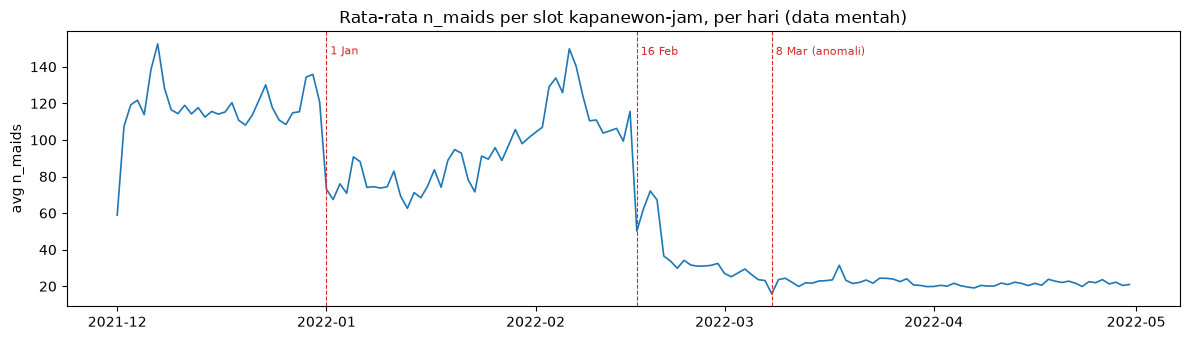

In [8]:
daily = df_presence.assign(date=p_dates).groupby("date").agg(
    avg_maids_per_slot=("n_maids", "mean"),
    total_pings=("n_pings", "sum"),
)

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(daily.index, daily["avg_maids_per_slot"], lw=1.2)
for d, label in [("2022-01-01", "1 Jan"), ("2022-02-16", "16 Feb"), ("2022-03-08", "8 Mar (anomali)")]:
    ax.axvline(pd.Timestamp(d), color="tab:red", ls="--", lw=0.8)
    ax.text(pd.Timestamp(d), ax.get_ylim()[1] * 0.95, " " + label, color="tab:red", fontsize=8, va="top")
ax.set_title("Rata-rata n_maids per slot kapanewon-jam, per hari (data mentah)")
ax.set_ylabel("avg n_maids")
plt.tight_layout()
plt.show()

### 2.3 Konsistensi Wilayah & Relasi Kode–Nama (`kapanewon_code` vs `kapanewon`)

In [9]:
p_codes = set(df_presence["kapanewon_code"].unique())
o_codes = set(df_od["origin_code"].unique())
d_codes = set(df_od["dest_code"].unique())

print("Jumlah kapanewon_code unik (presence, origin, dest):", len(p_codes), len(o_codes), len(d_codes))
print("Semua kode wilayah identik di kedua dataset?", p_codes == o_codes == d_codes)

dim_check = pd.concat([
    df_presence[["kab_code", "kab_kota", "kapanewon_code", "kapanewon"]].drop_duplicates(),
    df_od[["origin_kab_code", "origin_kab_kota", "origin_code", "origin_kapanewon"]].rename(
        columns={"origin_kab_code": "kab_code", "origin_kab_kota": "kab_kota", "origin_code": "kapanewon_code", "origin_kapanewon": "kapanewon"}
    ).drop_duplicates(),
    df_od[["dest_kab_code", "dest_kab_kota", "dest_code", "dest_kapanewon"]].rename(
        columns={"dest_kab_code": "kab_code", "dest_kab_kota": "kab_kota", "dest_code": "kapanewon_code", "dest_kapanewon": "kapanewon"}
    ).drop_duplicates(),
]).drop_duplicates()

print(f"Total pasangan (kode, nama) unik : {len(dim_check)}")
print("1 kode = 1 nama?                 :", dim_check["kapanewon_code"].is_unique)
print("Nama kapanewon yang dipakai > 1 kode (JOIN wajib pakai kode, bukan nama):")
display(dim_check[dim_check.duplicated(subset=["kapanewon"], keep=False)].sort_values("kapanewon"))

Jumlah kapanewon_code unik (presence, origin, dest): 78 78 78
Semua kode wilayah identik di kedua dataset? True
Total pasangan (kode, nama) unik : 78
1 kode = 1 nama?                 : True
Nama kapanewon yang dipakai > 1 kode (JOIN wajib pakai kode, bukan nama):


,kab_code,kab_kota,kapanewon_code,kapanewon
19,34.02,BANTUL,34.02.09,JETIS
54,34.71,YOGYAKARTA,34.71.02,JETIS


### 2.4 Distribusi Numerik & Kualitas Data (`reduced_quality`)

Untuk OD, `n_maids` = jumlah device unik dari origin *i* yang terlihat di tujuan *j* dalam satu bulan. Menjumlahkan lintas tujuan akan menghitung device yang sama berkali-kali, jadi perbandingan intra vs inter memakai mean/median per pasangan.

In [10]:
print("Statistik Numerik Presence")
display(df_presence[["n_maids", "n_pings"]].assign(pings_per_maid=df_presence["n_pings"] / df_presence["n_maids"]).describe().round(2))

print("Statistik Numerik OD Home Visits")
display(df_od[["n_maids"]].describe().round(2))

print("Sebaran reduced_quality per Bulan (jumlah baris)")
display(pd.crosstab(df_od["month"], df_od["reduced_quality"], margins=True))

print("Intra-Kapanewon vs Inter-Kapanewon (OD) per pasangan origin-dest")
od_flow = df_od.assign(flow_type=np.where(df_od["origin_code"] == df_od["dest_code"], "Intra-Kapanewon", "Inter-Kapanewon"))
display(od_flow.groupby(["month", "flow_type"]).agg(
    pairs=("n_maids", "count"),
    mean_maids=("n_maids", "mean"),
    median_maids=("n_maids", "median"),
    max_maids=("n_maids", "max"),
).round(2).unstack("flow_type"))

Statistik Numerik Presence


,n_maids,n_pings,pings_per_maid
count,230418.00,230418.00,230418.00
mean,72.01,191.42,2.61
std,124.18,369.30,1.15
min,5.00,5.00,1.00
25%,12.00,28.00,1.88
50%,29.00,72.00,2.39
75%,77.00,201.00,3.05
max,2506.00,10210.00,39.38


Statistik Numerik OD Home Visits


,n_maids
count,9894.00
mean,64.93
std,278.16
min,5.00
25%,8.00
50%,15.00
75%,38.00
max,7961.00


Sebaran reduced_quality per Bulan (jumlah baris)


reduced_quality,False,True,All
month,,,
2021-12,2595,0,2595
2022-01,2624,0,2624
2022-02,2653,0,2653
2022-03,0,1202,1202
2022-04,0,820,820
All,7872,2022,9894


Intra-Kapanewon vs Inter-Kapanewon (OD) per pasangan origin-dest


pairs                      mean_maids                  \
flow_type Inter-Kapanewon Intra-Kapanewon Inter-Kapanewon Intra-Kapanewon   
month                                                                       
2021-12              2517              78           57.20         1348.33   
2022-01              2546              78           43.27          919.81   
2022-02              2575              78           39.21          741.62   
2022-03              1124              78           16.57          140.28   
2022-04               742              78           16.42          138.40   

             median_maids                       max_maids                  
flow_type Inter-Kapanewon Intra-Kapanewon Inter-Kapanewon Intra-Kapanewon  
month                                                                      
2021-12              17.0           730.5            2661            7961  
2022-01              16.0           526.5            1185            6644  
2022-02              15.0           373.5             897            5532  
2022-03              10.0            84.5             461             779  
2022-04              10.0            53.5             692             913

---
## 3. Data Cleaning & Transformation

Hasil audit Section 2: tidak ada *missing value* maupun duplikat. Fokus transformasi:
1. **Standarisasi kode & nama wilayah** (strip, upper). Kode tetap string.
2. **Fitur waktu & surrogate key** (`date_key` `YYYYMMDD`, `month_key` `YYYYMM`) sebagai persiapan dimensi `dim_date`, `dim_hour`, `dim_month`. Grain presence = jam, grain OD = bulan.
3. **Flag kualitas.** `is_holiday`, `is_anomaly` (8 Mar 2022) di presence; `reduced_quality` di OD. Data **tidak dibuang**; filter dilakukan saat analisis.
4. **Normalisasi.** `maids_share` (share device di kapanewon terhadap seluruh DIY pada jam yang sama) dan `visitor_share_dest` (share pengunjung dari tiap origin terhadap seluruh pengunjung tujuan pada bulan itu).
5. Simpan hasil ke `staging.presence_clean` dan `staging.od_clean`.

### 3.1 Transformasi `df_presence` → `df_presence_clean`

In [12]:
# Hari libur nasional dalam periode data (Des 2021 – Apr 2022). Verifikasi dengan SKB 3 Menteri.
HOLIDAYS = {
    "2021-12-25": "Hari Raya Natal",
    "2022-01-01": "Tahun Baru Masehi",
    "2022-02-01": "Tahun Baru Imlek",
    "2022-02-28": "Isra Mi'raj",
    "2022-03-03": "Hari Raya Nyepi",
    "2022-04-15": "Wafat Isa Almasih",
}
ANOMALY_DATES = {"2022-03-08"}  # README Section 6.3: drop 1 hari, kemungkinan masalah pengiriman data

df_presence_clean = df_presence.copy()

# Standarisasi kode & nama wilayah
for col in ["kab_code", "kapanewon_code"]:
    df_presence_clean[col] = df_presence_clean[col].str.strip()
for col in ["kab_kota", "kapanewon"]:
    df_presence_clean[col] = df_presence_clean[col].str.strip().str.upper()

# Parsing tanggal & fitur waktu
df_presence_clean["date"] = pd.to_datetime(df_presence_clean["date"])
date_str = df_presence_clean["date"].dt.strftime("%Y-%m-%d")
df_presence_clean["date_key"] = df_presence_clean["date"].dt.strftime("%Y%m%d").astype(int)
df_presence_clean["month"] = df_presence_clean["date"].dt.strftime("%Y-%m")
df_presence_clean["month_key"] = df_presence_clean["date"].dt.strftime("%Y%m").astype(int)
df_presence_clean["day_of_week"] = df_presence_clean["date"].dt.day_of_week  # 0=Senin, 6=Minggu
df_presence_clean["day_name"] = df_presence_clean["date"].dt.day_name()
df_presence_clean["is_weekend"] = df_presence_clean["day_of_week"] >= 5
df_presence_clean["is_holiday"] = date_str.isin(HOLIDAYS.keys())
df_presence_clean["is_anomaly"] = date_str.isin(ANOMALY_DATES)

# Pengelompokan jam aktivitas
df_presence_clean["time_slot"] = pd.cut(
    df_presence_clean["hour"],
    bins=[-1, 5, 9, 14, 18, 23],
    labels=["00-05 Dini Hari", "06-09 Pagi", "10-14 Siang", "15-18 Sore", "19-23 Malam"],
).astype(str)
df_presence_clean["is_daytime"] = df_presence_clean["hour"].between(8, 17)  # definisi daytime OD (08:00–17:59)
df_presence_clean["is_night"] = df_presence_clean["hour"].between(0, 5)     # definisi validasi dataset (00–05)

# Metrik turunan
df_presence_clean["pings_per_maid"] = (df_presence_clean["n_pings"] / df_presence_clean["n_maids"]).round(4)

# Normalisasi: share device kapanewon terhadap total seluruh kapanewon yang terpublikasi pada (tanggal, jam) yang sama.
# Menghilangkan efek turunnya ukuran sampel antar waktu sehingga tren bisa dibandingkan.
slot_total = df_presence_clean.groupby(["date_key", "hour"])["n_maids"].transform("sum")
df_presence_clean["maids_share"] = df_presence_clean["n_maids"] / slot_total

print("Shape df_presence_clean:", df_presence_clean.shape)
print("Baris is_holiday:", int(df_presence_clean["is_holiday"].sum()), "| baris is_anomaly:", int(df_presence_clean["is_anomaly"].sum()))
print("Cek normalisasi (total share per slot = 1):",
      np.allclose(df_presence_clean.groupby(["date_key", "hour"])["maids_share"].sum(), 1.0))
display(df_presence_clean.head())

Shape df_presence_clean: (230418, 21)
Baris is_holiday: 9407 | baris is_anomaly: 993
Cek normalisasi (total share per slot = 1): True


,kab_code,kab_kota,kapanewon_code,kapanewon,date,hour,n_maids,n_pings,date_key,month,month_key,day_of_week,day_name,is_weekend,is_holiday,is_anomaly,time_slot,is_daytime,is_night,pings_per_maid,maids_share
0,34.01,KULON PROGO,34.01.01,TEMON,2021-12-01,0,16,66,20211201,2021-12,202112,2,Wednesday,False,False,False,00-05 Dini Hari,False,True,4.1250,0.004207
1,34.01,KULON PROGO,34.01.02,WATES,2021-12-01,0,58,101,20211201,2021-12,202112,2,Wednesday,False,False,False,00-05 Dini Hari,False,True,1.7414,0.015251
2,34.01,KULON PROGO,34.01.03,PANJATAN,2021-12-01,0,11,32,20211201,2021-12,202112,2,Wednesday,False,False,False,00-05 Dini Hari,False,True,2.9091,0.002892
3,34.01,KULON PROGO,34.01.04,GALUR,2021-12-01,0,9,50,20211201,2021-12,202112,2,Wednesday,False,False,False,00-05 Dini Hari,False,True,5.5556,0.002367
4,34.01,KULON PROGO,34.01.05,LENDAH,2021-12-01,0,14,74,20211201,2021-12,202112,2,Wednesday,False,False,False,00-05 Dini Hari,False,True,5.2857,0.003681


> Catatan: `maids_share` adalah share *device-presence* antar kapanewon, bukan share populasi. Karena kapanewon yang disuppress (< 5 device) tidak ikut di penyebut, share wilayah rural pada jam sepi sedikit bias. Ini dicatat sebagai keterbatasan.

### 3.2 Transformasi `df_od` → `df_od_clean`

In [13]:
df_od_clean = df_od.copy()

# Standarisasi kode & nama wilayah
code_cols = ["origin_kab_code", "origin_code", "dest_kab_code", "dest_code"]
name_cols = ["origin_kab_kota", "origin_kapanewon", "dest_kab_kota", "dest_kapanewon"]
for col in code_cols:
    df_od_clean[col] = df_od_clean[col].str.strip()
for col in name_cols:
    df_od_clean[col] = df_od_clean[col].str.strip().str.upper()

# Bulan & surrogate key
df_od_clean["month"] = df_od_clean["month"].str.strip()
df_od_clean["month_key"] = df_od_clean["month"].str.replace("-", "", regex=False).astype(int)

# Flag kualitas: pastikan boolean asli (bukan string "False", yang bernilai True jika di-astype(bool))
if df_od_clean["reduced_quality"].dtype != bool:
    df_od_clean["reduced_quality"] = df_od_clean["reduced_quality"].astype(str).str.strip().str.lower().map({"true": True, "false": False})
assert df_od_clean["reduced_quality"].notna().all()
df_od_clean["is_full_quality"] = ~df_od_clean["reduced_quality"]

# Klasifikasi cakupan pergerakan
df_od_clean["flow_scope"] = np.select(
    [
        df_od_clean["origin_code"] == df_od_clean["dest_code"],
        df_od_clean["origin_kab_code"] == df_od_clean["dest_kab_code"],
    ],
    ["Intra-Kapanewon", "Antar-Kapanewon (Dalam Kab/Kota)"],
    default="Lintas Kab/Kota",
)

# Normalisasi: share pengunjung dari tiap origin terhadap seluruh pengunjung tujuan pada bulan yang sama.
# SUM lintas origin valid karena tiap device hanya punya 1 home per bulan.
dest_total = df_od_clean.groupby(["month_key", "dest_code"])["n_maids"].transform("sum")
df_od_clean["visitor_share_dest"] = df_od_clean["n_maids"] / dest_total

print("Shape df_od_clean:", df_od_clean.shape)
print("\nreduced_quality per bulan:")
display(df_od_clean.groupby("month")["reduced_quality"].agg(["first", "count"]))
print("Distribusi flow_scope (jumlah pasangan origin-dest per bulan):")
display(pd.crosstab(df_od_clean["month"], df_od_clean["flow_scope"]))
display(df_od_clean.head())

Shape df_od_clean: (9894, 15)

reduced_quality per bulan:


,first,count
month,,
2021-12,False,2595
2022-01,False,2624
2022-02,False,2653
2022-03,True,1202
2022-04,True,820


Distribusi flow_scope (jumlah pasangan origin-dest per bulan):


flow_scope,Antar-Kapanewon (Dalam Kab/Kota),Intra-Kapanewon,Lintas Kab/Kota
month,,,
2021-12,789,78,1728
2022-01,808,78,1738
2022-02,809,78,1766
2022-03,496,78,628
2022-04,326,78,416


,month,origin_kab_code,origin_kab_kota,origin_code,origin_kapanewon,dest_kab_code,dest_kab_kota,dest_code,dest_kapanewon,n_maids,reduced_quality,month_key,is_full_quality,flow_scope,visitor_share_dest
0,2021-12,34.01,KULON PROGO,34.01.01,TEMON,34.01,KULON PROGO,34.01.01,TEMON,569,False,202112,True,Intra-Kapanewon,0.438705
1,2021-12,34.01,KULON PROGO,34.01.01,TEMON,34.01,KULON PROGO,34.01.02,WATES,85,False,202112,True,Antar-Kapanewon (Dalam Kab/Kota),0.022849
2,2021-12,34.01,KULON PROGO,34.01.01,TEMON,34.01,KULON PROGO,34.01.03,PANJATAN,42,False,202112,True,Antar-Kapanewon (Dalam Kab/Kota),0.112000
3,2021-12,34.01,KULON PROGO,34.01.01,TEMON,34.01,KULON PROGO,34.01.04,GALUR,16,False,202112,True,Antar-Kapanewon (Dalam Kab/Kota),0.029197
4,2021-12,34.01,KULON PROGO,34.01.01,TEMON,34.01,KULON PROGO,34.01.05,LENDAH,8,False,202112,True,Antar-Kapanewon (Dalam Kab/Kota),0.009639


### 3.3 Load Hasil Transform → Staging (Clean)

Seluruh periode tetap disimpan. Pembatasan analisis OD ke **Des 2021 – Feb 2022** (`reduced_quality = False`) dan pengecualian `is_anomaly` dilakukan di tahap analitik.

In [14]:
for df, table in [(df_presence_clean, "staging.presence_clean"), (df_od_clean, "staging.od_clean")]:
    n = load_to_duckdb(df, table)
    print(f"{table:<24} {n:>8,} baris  {'OK' if n == len(df) else 'MISMATCH'}")

display(con.sql("""
    SELECT schema_name, table_name, estimated_size AS approx_rows, column_count
    FROM duckdb_tables() ORDER BY schema_name, table_name
""").df())

staging.presence_clean    230,418 baris  OK
staging.od_clean            9,894 baris  OK


,schema_name,table_name,approx_rows,column_count
0,dw,dim_date,151,10
1,dw,dim_hour,24,4
2,dw,dim_kapanewon,78,5
3,dw,dim_month,5,5
4,dw,fact_hourly_presence,230418,7
5,dw,fact_monthly_od,9894,7
6,staging,od_clean,9894,15
7,staging,od_raw,9894,11
8,staging,presence_clean,230418,21
9,staging,presence_raw,230418,8


---
## 4. Build Data Warehouse (`dw`)

Tahap ini membangun **galaxy schema** (*fact constellation*) di schema `dw` dari `staging.*_clean`. Semuanya SQL (`CREATE OR REPLACE TABLE` + `INSERT ... SELECT`), jadi sel bisa dijalankan ulang tanpa error.

```
                 dim_date ──┐           ┌── dim_month
                 dim_hour ──┤           │
                            ▼           ▼
dim_kapanewon ──► fact_hourly_presence   fact_monthly_od ◄── dim_kapanewon (origin & dest)
```

Keputusan desain:
- **Dua fakta, dua grain waktu.** Presence per jam memakai `dim_date` + `dim_hour`; OD per bulan memakai `dim_month`. Keduanya tidak dipaksa jadi satu `dim_time`.
- **`dim_kapanewon` dipakai bersama** oleh kedua fakta dan berperan ganda (*role-playing*) sebagai origin dan dest di OD.
- **Join pakai kode** (`kapanewon_code`), bukan nama. `JETIS` ada di Bantul (`34.02.09`) dan Kota Yogyakarta (`34.71.02`).
- **PK dideklarasikan di dimensi, FK tidak.** DuckDB menolak `CREATE OR REPLACE` pada tabel yang direferensikan FK (*"main key table of the table ..."*), sehingga notebook tidak lagi idempoten. Integritas referensial dan duplikat grain diperiksa di section QC.
- **Measure turunan dihitung ulang di SQL** dari measure mentah (`pings_per_maid`, `maids_share`, `visitor_share_dest`), lalu dicocokkan dengan hasil Pandas di QC.

### 4.1 Dimensi

| Dimensi | Grain | Sumber |
|---|---|---|
| `dim_kapanewon` | 1 baris = 1 kapanewon (78) | gabungan kolom wilayah presence + origin + dest OD |
| `dim_date` | 1 baris = 1 hari (151) | tanggal unik `presence_clean` |
| `dim_hour` | 1 baris = 1 jam (24) | dibangkitkan (`range(0, 24)`) |
| `dim_month` | 1 baris = 1 bulan (5) | bulan unik presence + OD; `reduced_quality` dari OD |

`day_of_week`: 0 = Senin … 6 = Minggu. `week_of_year`: minggu ISO (1–2 Jan 2022 masuk minggu 52). `is_city` = Kota Yogyakarta (`kab_code = '34.71'`). Nama kab/kota tetap memakai nilai sumber (`YOGYAKARTA`).

In [15]:
def run_sql(statements):
    """Jalankan DDL/DML berurutan. fetchall() menghabiskan hasil sebelum statement berikutnya (DuckDB 2.x)."""
    for stmt in statements:
        con.execute(stmt).fetchall()


DDL_DIMENSIONS = [
    # ---------- dim_kapanewon ----------
    """
    CREATE OR REPLACE TABLE dw.dim_kapanewon (
        kapanewon_code VARCHAR PRIMARY KEY,
        kapanewon_name VARCHAR NOT NULL,
        kab_code       VARCHAR NOT NULL,
        kab_kota       VARCHAR NOT NULL,
        is_city        BOOLEAN NOT NULL
    )
    """,
    # UNION (bukan UNION ALL) membuang duplikat; jika 1 kode punya 2 nama, INSERT gagal di PK.
    """
    INSERT INTO dw.dim_kapanewon
    SELECT kapanewon_code, kapanewon, kab_code, kab_kota, kab_code = '34.71'
    FROM (
        SELECT kapanewon_code, kapanewon, kab_code, kab_kota FROM staging.presence_clean
        UNION
        SELECT origin_code, origin_kapanewon, origin_kab_code, origin_kab_kota FROM staging.od_clean
        UNION
        SELECT dest_code, dest_kapanewon, dest_kab_code, dest_kab_kota FROM staging.od_clean
    )
    ORDER BY kapanewon_code
    """,
    # ---------- dim_date ----------
    """
    CREATE OR REPLACE TABLE dw.dim_date (
        date_key     INTEGER PRIMARY KEY,   -- YYYYMMDD
        date         DATE     NOT NULL,
        day          TINYINT  NOT NULL,
        day_of_week  TINYINT  NOT NULL,     -- 0 = Senin ... 6 = Minggu
        day_name     VARCHAR  NOT NULL,
        is_weekend   BOOLEAN  NOT NULL,
        week_of_year TINYINT  NOT NULL,     -- minggu ISO
        month_key    INTEGER  NOT NULL,     -- FK logis ke dim_month
        is_holiday   BOOLEAN  NOT NULL,
        is_anomaly   BOOLEAN  NOT NULL      -- 2022-03-08: dikecualikan dari analisis tren
    )
    """,
    """
    INSERT INTO dw.dim_date
    SELECT DISTINCT
        date_key,
        CAST(date AS DATE),
        day(CAST(date AS DATE)),
        day_of_week,
        day_name,
        is_weekend,
        weekofyear(CAST(date AS DATE)),
        month_key,
        is_holiday,
        is_anomaly
    FROM staging.presence_clean
    ORDER BY date_key
    """,
    # ---------- dim_hour ----------
    """
    CREATE OR REPLACE TABLE dw.dim_hour (
        hour       TINYINT PRIMARY KEY,
        time_slot  VARCHAR NOT NULL,
        is_daytime BOOLEAN NOT NULL,        -- 08-17, definisi daytime OD
        is_night   BOOLEAN NOT NULL         -- 00-05, definisi validasi dataset
    )
    """,
    """
    INSERT INTO dw.dim_hour
    SELECT
        h,
        CASE WHEN h <= 5  THEN '00-05 Dini Hari'
             WHEN h <= 9  THEN '06-09 Pagi'
             WHEN h <= 14 THEN '10-14 Siang'
             WHEN h <= 18 THEN '15-18 Sore'
             ELSE              '19-23 Malam' END,
        h BETWEEN 8 AND 17,
        h BETWEEN 0 AND 5
    FROM range(0, 24) AS t(h)
    """,
    # ---------- dim_month ----------
    """
    CREATE OR REPLACE TABLE dw.dim_month (
        month_key       INTEGER PRIMARY KEY,   -- YYYYMM
        month           VARCHAR  NOT NULL,     -- YYYY-MM
        month_name      VARCHAR  NOT NULL,
        year            SMALLINT NOT NULL,
        reduced_quality BOOLEAN  NOT NULL      -- Mar-Apr 2022 = TRUE
    )
    """,
    """
    INSERT INTO dw.dim_month
    SELECT
        m.month_key,
        m.month,
        monthname(strptime(m.month || '-01', '%Y-%m-%d')),
        CAST(left(m.month, 4) AS SMALLINT),
        COALESCE(q.reduced_quality, FALSE)
    FROM (
        SELECT DISTINCT month_key, month FROM staging.presence_clean
        UNION
        SELECT DISTINCT month_key, month FROM staging.od_clean
    ) AS m
    LEFT JOIN (
        SELECT month_key, bool_or(reduced_quality) AS reduced_quality
        FROM staging.od_clean GROUP BY month_key
    ) AS q USING (month_key)
    ORDER BY m.month_key
    """,
]

run_sql(DDL_DIMENSIONS)

for t in ["dim_kapanewon", "dim_date", "dim_hour", "dim_month"]:
    print(f"dw.{t}")
    display(con.sql(f"SELECT * FROM dw.{t} ORDER BY 1 LIMIT 5").df())

dw.dim_kapanewon


,kapanewon_code,kapanewon_name,kab_code,kab_kota,is_city
0,34.01.01,TEMON,34.01,KULON PROGO,False
1,34.01.02,WATES,34.01,KULON PROGO,False
2,34.01.03,PANJATAN,34.01,KULON PROGO,False
3,34.01.04,GALUR,34.01,KULON PROGO,False
4,34.01.05,LENDAH,34.01,KULON PROGO,False


dw.dim_date


,date_key,date,day,day_of_week,day_name,is_weekend,week_of_year,month_key,is_holiday,is_anomaly
0,20211201,2021-12-01,1,2,Wednesday,False,48,202112,False,False
1,20211202,2021-12-02,2,3,Thursday,False,48,202112,False,False
2,20211203,2021-12-03,3,4,Friday,False,48,202112,False,False
3,20211204,2021-12-04,4,5,Saturday,True,48,202112,False,False
4,20211205,2021-12-05,5,6,Sunday,True,48,202112,False,False


dw.dim_hour


,hour,time_slot,is_daytime,is_night
0,0,00-05 Dini Hari,False,True
1,1,00-05 Dini Hari,False,True
2,2,00-05 Dini Hari,False,True
3,3,00-05 Dini Hari,False,True
4,4,00-05 Dini Hari,False,True


dw.dim_month


,month_key,month,month_name,year,reduced_quality
0,202112,2021-12,December,2021,False
1,202201,2022-01,January,2022,False
2,202202,2022-02,February,2022,False
3,202203,2022-03,March,2022,True
4,202204,2022-04,April,2022,True


### 4.2 Tabel Fakta

| Fakta | Grain | Measure |
|---|---|---|
| `fact_hourly_presence` | kapanewon × tanggal × jam | `n_maids` (non-aditif), `n_pings` (aditif), `pings_per_maid`, `maids_share` |
| `fact_monthly_od` | bulan × origin × dest | `n_maids` (non-aditif lintas dest), `visitor_share_dest` |

> `SUM(n_maids) OVER (PARTITION BY date_key, hour)` di bawah hanya dipakai sebagai **penyebut normalisasi** `maids_share`. Angkanya tidak pernah dilaporkan sebagai jumlah device. Penyebutnya hanya mencakup kapanewon yang terpublikasi (slot < 5 device tidak ada), jadi share wilayah rural pada jam sepi sedikit bias.
>
> Di OD, `SUM` lintas origin untuk satu tujuan valid (satu device punya satu home per bulan). Itulah penyebut `visitor_share_dest`.

In [16]:
DDL_FACTS = [
    # ---------- fact_hourly_presence ----------
    """
    CREATE OR REPLACE TABLE dw.fact_hourly_presence (
        kapanewon_code VARCHAR  NOT NULL,   -- FK logis ke dim_kapanewon
        date_key       INTEGER  NOT NULL,   -- FK logis ke dim_date
        hour           TINYINT  NOT NULL,   -- FK logis ke dim_hour
        n_maids        INTEGER  NOT NULL,
        n_pings        INTEGER  NOT NULL,
        pings_per_maid DOUBLE   NOT NULL,
        maids_share    DOUBLE   NOT NULL
    )
    """,
    """
    INSERT INTO dw.fact_hourly_presence
    SELECT
        kapanewon_code,
        date_key,
        hour,
        n_maids,
        n_pings,
        n_pings * 1.0 / n_maids,
        n_maids * 1.0 / SUM(n_maids) OVER (PARTITION BY date_key, hour)
    FROM staging.presence_clean
    ORDER BY date_key, hour, kapanewon_code
    """,
    # ---------- fact_monthly_od ----------
    """
    CREATE OR REPLACE TABLE dw.fact_monthly_od (
        month_key          INTEGER NOT NULL,  -- FK logis ke dim_month
        origin_code        VARCHAR NOT NULL,  -- FK logis ke dim_kapanewon (origin)
        dest_code          VARCHAR NOT NULL,  -- FK logis ke dim_kapanewon (dest)
        flow_scope         VARCHAR NOT NULL,
        reduced_quality    BOOLEAN NOT NULL,
        n_maids            INTEGER NOT NULL,
        visitor_share_dest DOUBLE  NOT NULL
    )
    """,
    """
    INSERT INTO dw.fact_monthly_od
    SELECT
        month_key,
        origin_code,
        dest_code,
        flow_scope,
        reduced_quality,
        n_maids,
        n_maids * 1.0 / SUM(n_maids) OVER (PARTITION BY month_key, dest_code)
    FROM staging.od_clean
    ORDER BY month_key, dest_code, origin_code
    """,
]

run_sql(DDL_FACTS)

for t in ["fact_hourly_presence", "fact_monthly_od"]:
    print(f"dw.{t}")
    display(con.sql(f"SELECT * FROM dw.{t} LIMIT 5").df())

dw.fact_hourly_presence


,kapanewon_code,date_key,hour,n_maids,n_pings,pings_per_maid,maids_share
0,34.01.01,20211201,0,16,66,4.125000,0.004207
1,34.01.02,20211201,0,58,101,1.741379,0.015251
2,34.01.03,20211201,0,11,32,2.909091,0.002892
3,34.01.04,20211201,0,9,50,5.555556,0.002367
4,34.01.05,20211201,0,14,74,5.285714,0.003681


dw.fact_monthly_od


,month_key,origin_code,dest_code,flow_scope,reduced_quality,n_maids,visitor_share_dest
0,202112,34.01.01,34.01.01,Intra-Kapanewon,False,569,0.438705
1,202112,34.01.02,34.01.01,Antar-Kapanewon (Dalam Kab/Kota),False,65,0.050116
2,202112,34.01.03,34.01.01,Antar-Kapanewon (Dalam Kab/Kota),False,11,0.008481
3,202112,34.01.05,34.01.01,Antar-Kapanewon (Dalam Kab/Kota),False,11,0.008481
4,202112,34.01.06,34.01.01,Antar-Kapanewon (Dalam Kab/Kota),False,55,0.042406


### 4.3 Verifikasi Cepat DW

Cek ringkas bahwa DW terbentuk: jumlah baris per tabel dibandingkan dengan ekspektasi, lalu beberapa query *join* lewat kode wilayah. Pemeriksaan lengkap (orphan FK, duplikat grain, range nilai, kecocokan measure dengan Pandas) ada di section QC.

In [17]:
EXPECTED_ROWS = {
    "dim_kapanewon": 78,
    "dim_date": 151,
    "dim_hour": 24,
    "dim_month": 5,
    "fact_hourly_presence": con.execute("SELECT COUNT(*) FROM staging.presence_clean").fetchall()[0][0],
    "fact_monthly_od": con.execute("SELECT COUNT(*) FROM staging.od_clean").fetchall()[0][0],
}

rows = []
for table, expected in EXPECTED_ROWS.items():
    actual = con.execute(f"SELECT COUNT(*) FROM dw.{table}").fetchall()[0][0]
    rows.append({"tabel": f"dw.{table}", "baris": actual, "ekspektasi": expected,
                 "status": "OK" if actual == expected else "MISMATCH"})
display(pd.DataFrame(rows))

print("Join lewat KODE: nama JETIS muncul 2x di dim_kapanewon")
display(con.sql("""
    SELECT kapanewon_code, kapanewon_name, kab_kota
    FROM dw.dim_kapanewon WHERE kapanewon_name = 'JETIS' ORDER BY kapanewon_code
""").df())

print("Presence: rata-rata (bukan SUM) n_maids per slot kapanewon-jam, per kab/kota (tanpa 8 Mar 2022)")
display(con.sql("""
    SELECT k.kab_kota,
           COUNT(DISTINCT k.kapanewon_code)  AS kapanewon,
           ROUND(AVG(f.n_maids), 1)          AS avg_maids_per_slot,
           SUM(f.n_pings)                    AS total_pings        -- n_pings aditif
    FROM dw.fact_hourly_presence f
    JOIN dw.dim_kapanewon k USING (kapanewon_code)
    JOIN dw.dim_date d      USING (date_key)
    WHERE NOT d.is_anomaly
    GROUP BY k.kab_kota ORDER BY avg_maids_per_slot DESC
""").df())

print("OD (Des 2021): 5 aliran antar-kapanewon terbesar (origin -> dest, role-playing dim_kapanewon)")
display(con.sql("""
    SELECT o.kapanewon_name AS origin, o.kab_kota AS origin_kab,
           d.kapanewon_name AS dest,   d.kab_kota AS dest_kab,
           f.n_maids, ROUND(f.visitor_share_dest, 3) AS visitor_share_dest
    FROM dw.fact_monthly_od f
    JOIN dw.dim_kapanewon o ON f.origin_code = o.kapanewon_code
    JOIN dw.dim_kapanewon d ON f.dest_code   = d.kapanewon_code
    WHERE f.month_key = 202112 AND f.flow_scope <> 'Intra-Kapanewon'
    ORDER BY f.n_maids DESC LIMIT 5
""").df())

,tabel,baris,ekspektasi,status
0,dw.dim_kapanewon,78,78,OK
1,dw.dim_date,151,151,OK
2,dw.dim_hour,24,24,OK
3,dw.dim_month,5,5,OK
4,dw.fact_hourly_presence,230418,230418,OK
5,dw.fact_monthly_od,9894,9894,OK


Join lewat KODE: nama JETIS muncul 2x di dim_kapanewon


,kapanewon_code,kapanewon_name,kab_kota
0,34.02.09,JETIS,BANTUL
1,34.71.02,JETIS,YOGYAKARTA


Presence: rata-rata (bukan SUM) n_maids per slot kapanewon-jam, per kab/kota (tanpa 8 Mar 2022)


,kab_kota,kapanewon,avg_maids_per_slot,total_pings
0,SLEMAN,17,133.6,21110355.0
1,BANTUL,17,79.1,10256010.0
2,YOGYAKARTA,14,53.5,6853439.0
3,KULON PROGO,12,36.6,3404315.0
4,GUNUNGKIDUL,18,24.6,2445397.0


OD (Des 2021): 5 aliran antar-kapanewon terbesar (origin -> dest, role-playing dim_kapanewon)


,origin,origin_kab,dest,dest_kab,n_maids,visitor_share_dest
0,NGAGLIK,SLEMAN,PAKEM,SLEMAN,2661,0.233
1,GAMPING,SLEMAN,SEYEGAN,SLEMAN,1542,0.141
2,PAKEM,SLEMAN,NGAGLIK,SLEMAN,1478,0.092
3,BANGUNTAPAN,BANTUL,UMBULHARJO,YOGYAKARTA,1394,0.161
4,SEYEGAN,SLEMAN,GAMPING,SLEMAN,1342,0.083


---
## 5. Quality Check (QC)

Sebelum dipakai untuk analitik, isi DW (`dw.*`) diperiksa dulu. Setiap cek membandingkan nilai aktual dengan ekspektasi di `PLAN.md` bagian 4, lalu diberi status:

- `PASS`: sesuai ekspektasi.
- `FAIL`: tidak sesuai, harus dibenahi di Section 3 atau 4.
- `INFO`: bukan error, tetapi temuan yang perlu dicatat saat analisis.

| Section | Cek |
|---|---|
| 5.1 | Jumlah baris sama di tiap tahap (CSV, staging raw, staging clean, DW) |
| 5.2 | Jumlah baris dimensi dan kelengkapan tanggal |
| 5.3 | Null pada kolom kunci |
| 5.4 | Orphan FK (fakta tanpa pasangan di dimensi) |
| 5.5 | Duplikat grain dan PK |
| 5.6 | Range nilai |
| 5.7 | Total share hasil normalisasi = 1 |
| 5.8 | Hasil hitung SQL sama dengan Pandas |
| 5.9 | Konsistensi kode dan nama wilayah |
| 5.10 | Flag dan atribut turunan |
| 5.11 | Coverage per kapanewon |

Baris yang hilang berarti kurang dari 5 device (disuppress), bukan nol, jadi QC tidak pernah mengisinya dengan 0.

In [ ]:
QC_RESULTS = []   # (kelompok, cek, ekspektasi, aktual, status)


def q1(sql):
    """Jalankan query, kembalikan nilai tunggal (baris 1 kolom 1). fetchall() menghabiskan hasil (DuckDB 2.x)."""
    return con.execute(sql).fetchall()[0][0]


def qc(group, check, expected, actual, ok=None, level="strict"):
    """Catat 1 hasil cek.
    level="strict": PASS jika ok, FAIL jika tidak.
    level="info"  : selalu INFO (temuan yang dilaporkan, bukan error)."""
    if ok is None:
        ok = actual == expected
    status = "INFO" if level == "info" else ("PASS" if ok else "FAIL")
    QC_RESULTS.append({"kelompok": group, "cek": check, "ekspektasi": str(expected),
                       "aktual": str(actual), "status": status})
    return status


def qc_table(group):
    """Tampilkan hasil cek satu kelompok."""
    df = pd.DataFrame([r for r in QC_RESULTS if r["kelompok"] == group]).drop(columns="kelompok")
    display(df)

### 5.1 Rowcount per Tahap

Jumlah baris harus sama di setiap tahap, tidak boleh ada yang hilang atau bertambah saat load, transform, dan build DW. Ekspektasinya presence 230.418 baris dan OD 9.894 baris.

In [ ]:
EXPECTED_PRESENCE = 230_418
EXPECTED_OD = 9_894

stages = {
    "presence": [
        ("CSV (Pandas)",            len(df_presence)),
        ("staging.presence_raw",    q1("SELECT COUNT(*) FROM staging.presence_raw")),
        ("staging.presence_clean",  q1("SELECT COUNT(*) FROM staging.presence_clean")),
        ("dw.fact_hourly_presence", q1("SELECT COUNT(*) FROM dw.fact_hourly_presence")),
    ],
    "od": [
        ("CSV (Pandas)",            len(df_od)),
        ("staging.od_raw",          q1("SELECT COUNT(*) FROM staging.od_raw")),
        ("staging.od_clean",        q1("SELECT COUNT(*) FROM staging.od_clean")),
        ("dw.fact_monthly_od",      q1("SELECT COUNT(*) FROM dw.fact_monthly_od")),
    ],
}

for name, expected in [("presence", EXPECTED_PRESENCE), ("od", EXPECTED_OD)]:
    for stage, n in stages[name]:
        qc("5.1", f"Rowcount {name} @ {stage}", expected, n)

qc_table("5.1")

### 5.2 Jumlah Baris Dimensi & Kelengkapan Tanggal

Dimensi harus berisi 78 kapanewon, 151 hari (1 Des 2021 sampai 30 Apr 2022), 24 jam, dan 5 bulan. Tanggal juga harus berurutan tanpa celah, karena hari yang bolong akan terbaca sebagai hari tanpa aktivitas di analisis tren.

In [ ]:
dim_expected = {"dim_kapanewon": 78, "dim_date": 151, "dim_hour": 24, "dim_month": 5}
for t, exp in dim_expected.items():
    qc("5.2", f"Baris dw.{t}", exp, q1(f"SELECT COUNT(*) FROM dw.{t}"))

# Rentang & kontinuitas tanggal
d = con.sql("SELECT MIN(date) AS dmin, MAX(date) AS dmax, COUNT(*) AS n FROM dw.dim_date").df().iloc[0]
span_days = (pd.Timestamp(d["dmax"]) - pd.Timestamp(d["dmin"])).days + 1
qc("5.2", "dim_date: rentang tanggal", "2021-12-01 s.d. 2022-04-30",
   f"{pd.Timestamp(d['dmin']).date()} s.d. {pd.Timestamp(d['dmax']).date()}")
qc("5.2", "dim_date: tanggal berurutan tanpa celah (rentang hari = jumlah baris)", int(d["n"]), span_days)

# Jumlah kab/kota
qc("5.2", "Jumlah kab/kota di dim_kapanewon", 5, q1("SELECT COUNT(DISTINCT kab_code) FROM dw.dim_kapanewon"))
qc("5.2", "Kota Yogyakarta (is_city) punya 14 kapanewon", 14,
   q1("SELECT COUNT(*) FROM dw.dim_kapanewon WHERE is_city"))

qc_table("5.2")

### 5.3 Null pada Kolom Kunci

Seluruh kolom di tabel fakta dan dimensi tidak boleh null. DDL sudah memakai `NOT NULL`, jadi cek ini memastikan datanya memang terisi semua.

In [ ]:
def null_count(table, cols):
    expr = " + ".join(f"COUNT(*) FILTER (WHERE {c} IS NULL)" for c in cols)
    return q1(f"SELECT {expr} FROM {table}")

null_targets = {
    "dw.fact_hourly_presence": ["kapanewon_code", "date_key", "hour", "n_maids", "n_pings", "pings_per_maid", "maids_share"],
    "dw.fact_monthly_od":      ["month_key", "origin_code", "dest_code", "flow_scope", "reduced_quality", "n_maids", "visitor_share_dest"],
    "dw.dim_kapanewon":        ["kapanewon_code", "kapanewon_name", "kab_code", "kab_kota", "is_city"],
    "dw.dim_date":             ["date_key", "date", "day", "day_of_week", "day_name", "is_weekend", "week_of_year", "month_key", "is_holiday", "is_anomaly"],
    "dw.dim_hour":             ["hour", "time_slot", "is_daytime", "is_night"],
    "dw.dim_month":            ["month_key", "month", "month_name", "year", "reduced_quality"],
}
for table, cols in null_targets.items():
    qc("5.3", f"Null pada {table} ({len(cols)} kolom)", 0, null_count(table, cols))

qc_table("5.3")

### 5.4 Orphan Foreign Key

Orphan adalah baris fakta yang kodenya tidak ada di dimensi. FK tidak dideklarasikan sebagai constraint (lihat Section 4), jadi integritas referensial dicek dengan `LEFT JOIN` ke dimensi lalu mencari yang tidak ketemu. Hasil yang diharapkan 0 di semua relasi.

In [ ]:
ORPHAN_CHECKS = [
    ("fact_hourly_presence.kapanewon_code ke dim_kapanewon",
     """SELECT COUNT(*) FROM dw.fact_hourly_presence f
        LEFT JOIN dw.dim_kapanewon k ON f.kapanewon_code = k.kapanewon_code
        WHERE k.kapanewon_code IS NULL"""),
    ("fact_hourly_presence.date_key ke dim_date",
     """SELECT COUNT(*) FROM dw.fact_hourly_presence f
        LEFT JOIN dw.dim_date d ON f.date_key = d.date_key
        WHERE d.date_key IS NULL"""),
    ("fact_hourly_presence.hour ke dim_hour",
     """SELECT COUNT(*) FROM dw.fact_hourly_presence f
        LEFT JOIN dw.dim_hour h ON f.hour = h.hour
        WHERE h.hour IS NULL"""),
    ("fact_monthly_od.origin_code ke dim_kapanewon",
     """SELECT COUNT(*) FROM dw.fact_monthly_od f
        LEFT JOIN dw.dim_kapanewon k ON f.origin_code = k.kapanewon_code
        WHERE k.kapanewon_code IS NULL"""),
    ("fact_monthly_od.dest_code ke dim_kapanewon",
     """SELECT COUNT(*) FROM dw.fact_monthly_od f
        LEFT JOIN dw.dim_kapanewon k ON f.dest_code = k.kapanewon_code
        WHERE k.kapanewon_code IS NULL"""),
    ("fact_monthly_od.month_key ke dim_month",
     """SELECT COUNT(*) FROM dw.fact_monthly_od f
        LEFT JOIN dw.dim_month m ON f.month_key = m.month_key
        WHERE m.month_key IS NULL"""),
    ("dim_date.month_key ke dim_month",
     """SELECT COUNT(*) FROM dw.dim_date d
        LEFT JOIN dw.dim_month m ON d.month_key = m.month_key
        WHERE m.month_key IS NULL"""),
]
for label, sql in ORPHAN_CHECKS:
    qc("5.4", f"Orphan {label}", 0, q1(sql))

qc_table("5.4")

### 5.5 Duplikat Grain & PK

Grain tabel fakta adalah kombinasi kolom FK-nya, jadi satu kombinasi tidak boleh muncul dua kali. Kalau ada duplikat, `AVG` dan `SUM` di analitik akan menghitung slot yang sama berulang. PK di tiap dimensi juga harus unik.

In [ ]:
qc("5.5", "Duplikat grain presence (kapanewon_code, date_key, hour)", 0, q1("""
    SELECT COUNT(*) FROM (
        SELECT kapanewon_code, date_key, hour FROM dw.fact_hourly_presence
        GROUP BY kapanewon_code, date_key, hour HAVING COUNT(*) > 1)
"""))
qc("5.5", "Duplikat grain OD (month_key, origin_code, dest_code)", 0, q1("""
    SELECT COUNT(*) FROM (
        SELECT month_key, origin_code, dest_code FROM dw.fact_monthly_od
        GROUP BY month_key, origin_code, dest_code HAVING COUNT(*) > 1)
"""))

for table, pk in [("dim_kapanewon", "kapanewon_code"), ("dim_date", "date_key"),
                  ("dim_hour", "hour"), ("dim_month", "month_key")]:
    qc("5.5", f"Duplikat PK dw.{table}.{pk}", 0,
       q1(f"SELECT COUNT(*) - COUNT(DISTINCT {pk}) FROM dw.{table}"))

qc_table("5.5")

### 5.6 Range Nilai

Batas yang harus berlaku:
- `hour` antara 0 dan 23.
- `n_maids` minimal 5. Slot di bawah 5 device sudah disuppress oleh penyedia data, jadi nilai di bawah itu menandakan ada masalah.
- `n_pings` minimal sama dengan `n_maids`, dan `pings_per_maid` minimal 1.
- `maids_share` dan `visitor_share_dest` ada di rentang (0, 1].

In [ ]:
range_checks = [
    ("hour di luar 0-23 (presence)",           "SELECT COUNT(*) FROM dw.fact_hourly_presence WHERE hour < 0 OR hour > 23"),
    ("n_maids < 5 (presence)",                 "SELECT COUNT(*) FROM dw.fact_hourly_presence WHERE n_maids < 5"),
    ("n_maids < 5 (OD)",                       "SELECT COUNT(*) FROM dw.fact_monthly_od WHERE n_maids < 5"),
    ("n_pings < n_maids (presence)",           "SELECT COUNT(*) FROM dw.fact_hourly_presence WHERE n_pings < n_maids"),
    ("pings_per_maid < 1 (presence)",          "SELECT COUNT(*) FROM dw.fact_hourly_presence WHERE pings_per_maid < 1"),
    ("maids_share di luar (0, 1]",             "SELECT COUNT(*) FROM dw.fact_hourly_presence WHERE maids_share <= 0 OR maids_share > 1"),
    ("visitor_share_dest di luar (0, 1]",      "SELECT COUNT(*) FROM dw.fact_monthly_od WHERE visitor_share_dest <= 0 OR visitor_share_dest > 1"),
    ("day_of_week di luar 0-6 (dim_date)",     "SELECT COUNT(*) FROM dw.dim_date WHERE day_of_week < 0 OR day_of_week > 6"),
]
for label, sql in range_checks:
    qc("5.6", f"Pelanggaran: {label}", 0, q1(sql))

qc_table("5.6")

print("Ringkasan nilai (hanya untuk dilaporkan, bukan agregasi n_maids):")
display(con.sql("""
    SELECT 'presence.n_maids' AS kolom, MIN(n_maids) AS min, MEDIAN(n_maids) AS median, MAX(n_maids) AS max FROM dw.fact_hourly_presence
    UNION ALL SELECT 'presence.n_pings', MIN(n_pings), MEDIAN(n_pings), MAX(n_pings) FROM dw.fact_hourly_presence
    UNION ALL SELECT 'od.n_maids',       MIN(n_maids), MEDIAN(n_maids), MAX(n_maids) FROM dw.fact_monthly_od
""").df())

### 5.7 Normalisasi (Total Share = 1)

`maids_share` dinormalisasi per (tanggal, jam) dan `visitor_share_dest` per (bulan, tujuan). Kalau normalisasinya benar, total share di tiap grup harus 1 (toleransi `1e-9` untuk floating point).

In [ ]:
TOL = 1e-9

bad_presence = q1(f"""
    SELECT COUNT(*) FROM (
        SELECT date_key, hour FROM dw.fact_hourly_presence
        GROUP BY date_key, hour HAVING ABS(SUM(maids_share) - 1) > {TOL})
""")
bad_od = q1(f"""
    SELECT COUNT(*) FROM (
        SELECT month_key, dest_code FROM dw.fact_monthly_od
        GROUP BY month_key, dest_code HAVING ABS(SUM(visitor_share_dest) - 1) > {TOL})
""")
n_slots = q1("SELECT COUNT(*) FROM (SELECT DISTINCT date_key, hour FROM dw.fact_hourly_presence)")
n_dests = q1("SELECT COUNT(*) FROM (SELECT DISTINCT month_key, dest_code FROM dw.fact_monthly_od)")

qc("5.7", f"Slot (tanggal, jam) dengan total maids_share bukan 1 (dari {n_slots} slot)", 0, bad_presence)
qc("5.7", f"Grup (bulan, tujuan) dengan total visitor_share_dest bukan 1 (dari {n_dests} grup)", 0, bad_od)

qc_table("5.7")

### 5.8 Kecocokan Measure SQL vs Pandas

`pings_per_maid`, `maids_share`, dan `visitor_share_dest` dihitung dua kali: di Pandas (Section 3, tersimpan di `staging.*_clean`) dan di SQL (Section 4, tersimpan di `dw.fact_*`). Hasil keduanya harus sama. Toleransi `pings_per_maid` dibuat `1e-4` karena versi Pandas dibulatkan 4 desimal.

In [ ]:
n_pp = q1("""
    SELECT COUNT(*) FROM dw.fact_hourly_presence f
    JOIN staging.presence_clean s
      ON f.kapanewon_code = s.kapanewon_code AND f.date_key = s.date_key AND f.hour = s.hour
""")
qc("5.8", "Baris presence yang cocok antara DW dan staging.clean", EXPECTED_PRESENCE, n_pp)

qc("5.8", "n_maids / n_pings presence: DW beda dengan staging", 0, q1("""
    SELECT COUNT(*) FROM dw.fact_hourly_presence f
    JOIN staging.presence_clean s
      ON f.kapanewon_code = s.kapanewon_code AND f.date_key = s.date_key AND f.hour = s.hour
    WHERE f.n_maids <> s.n_maids OR f.n_pings <> s.n_pings
"""))
qc("5.8", "pings_per_maid: |SQL - Pandas| > 1e-4", 0, q1("""
    SELECT COUNT(*) FROM dw.fact_hourly_presence f
    JOIN staging.presence_clean s
      ON f.kapanewon_code = s.kapanewon_code AND f.date_key = s.date_key AND f.hour = s.hour
    WHERE ABS(f.pings_per_maid - s.pings_per_maid) > 0.0001
"""))
qc("5.8", "maids_share: |SQL - Pandas| > 1e-9", 0, q1("""
    SELECT COUNT(*) FROM dw.fact_hourly_presence f
    JOIN staging.presence_clean s
      ON f.kapanewon_code = s.kapanewon_code AND f.date_key = s.date_key AND f.hour = s.hour
    WHERE ABS(f.maids_share - s.maids_share) > 1e-9
"""))

qc("5.8", "Baris OD yang cocok antara DW dan staging.clean", EXPECTED_OD, q1("""
    SELECT COUNT(*) FROM dw.fact_monthly_od f
    JOIN staging.od_clean s
      ON f.month_key = s.month_key AND f.origin_code = s.origin_code AND f.dest_code = s.dest_code
"""))
qc("5.8", "n_maids / flow_scope / reduced_quality OD: DW beda dengan staging", 0, q1("""
    SELECT COUNT(*) FROM dw.fact_monthly_od f
    JOIN staging.od_clean s
      ON f.month_key = s.month_key AND f.origin_code = s.origin_code AND f.dest_code = s.dest_code
    WHERE f.n_maids <> s.n_maids OR f.flow_scope <> s.flow_scope OR f.reduced_quality <> s.reduced_quality
"""))
qc("5.8", "visitor_share_dest: |SQL - Pandas| > 1e-9", 0, q1("""
    SELECT COUNT(*) FROM dw.fact_monthly_od f
    JOIN staging.od_clean s
      ON f.month_key = s.month_key AND f.origin_code = s.origin_code AND f.dest_code = s.dest_code
    WHERE ABS(f.visitor_share_dest - s.visitor_share_dest) > 1e-9
"""))

qc_table("5.8")

### 5.9 Konsistensi Kode & Nama Wilayah

Join dilakukan lewat kode, jadi kode harus unik dan konsisten:
- Satu `kapanewon_code` hanya punya satu nama.
- Kode kapanewon (`34.02.09`) harus diawali kode kab/kota-nya (`34.02`).
- Nama yang dipakai lebih dari satu kode dicatat sebagai temuan. Yang diharapkan hanya `JETIS` (Bantul `34.02.09` dan Kota Yogyakarta `34.71.02`).

In [ ]:
qc("5.9", "Kode kapanewon dengan > 1 nama", 0, q1("""
    SELECT COUNT(*) FROM (
        SELECT kapanewon_code FROM dw.dim_kapanewon
        GROUP BY kapanewon_code HAVING COUNT(DISTINCT kapanewon_name) > 1)
"""))
qc("5.9", "kapanewon_code tidak diawali kab_code", 0, q1("""
    SELECT COUNT(*) FROM dw.dim_kapanewon
    WHERE substr(kapanewon_code, 1, length(kab_code)) <> kab_code
"""))
qc("5.9", "kab_code dengan > 1 nama kab/kota", 0, q1("""
    SELECT COUNT(*) FROM (
        SELECT kab_code FROM dw.dim_kapanewon
        GROUP BY kab_code HAVING COUNT(DISTINCT kab_kota) > 1)
"""))

dup_names = con.sql("""
    SELECT kapanewon_name, COUNT(*) AS n_kode,
           string_agg(kapanewon_code || ' (' || kab_kota || ')', ', ' ORDER BY kapanewon_code) AS kode
    FROM dw.dim_kapanewon
    GROUP BY kapanewon_name HAVING COUNT(*) > 1
    ORDER BY kapanewon_name
""").df()
qc("5.9", "Nama kapanewon dipakai > 1 kode (join wajib pakai kode)", "hanya JETIS",
   ", ".join(dup_names["kapanewon_name"]) if len(dup_names) else "tidak ada",
   ok=(list(dup_names["kapanewon_name"]) == ["JETIS"]))

qc_table("5.9")
display(dup_names)

### 5.10 Flag & Atribut Turunan

Flag ini dipakai langsung sebagai filter di analitik, jadi harus benar:
- `is_anomaly` hanya untuk 2022-03-08.
- `is_holiday` tepat pada 6 hari libur yang didefinisikan di Section 3.
- `reduced_quality` bernilai TRUE hanya untuk Mar dan Apr 2022, dan sama di `dim_month` maupun `fact_monthly_od`.
- `flow_scope` sesuai kode: origin = dest berarti Intra-Kapanewon, satu kab/kota berarti Antar-Kapanewon, selain itu Lintas Kab/Kota.
- `is_weekend` sesuai `day_of_week`, dan jumlah jam `is_daytime` serta `is_night` sesuai definisi.

In [ ]:
anom = con.sql("SELECT strftime(date, '%Y-%m-%d') AS d FROM dw.dim_date WHERE is_anomaly ORDER BY 1").df()["d"].tolist()
qc("5.10", "Tanggal is_anomaly", ["2022-03-08"], anom)

hol = con.sql("SELECT strftime(date, '%Y-%m-%d') AS d FROM dw.dim_date WHERE is_holiday ORDER BY 1").df()["d"].tolist()
qc("5.10", "Tanggal is_holiday (sama dengan HOLIDAYS di Section 3)", sorted(HOLIDAYS), hol)

rq = con.sql("SELECT month FROM dw.dim_month WHERE reduced_quality ORDER BY 1").df()["month"].tolist()
qc("5.10", "Bulan reduced_quality di dim_month", ["2022-03", "2022-04"], rq)

qc("5.10", "reduced_quality fakta OD beda dengan dim_month", 0, q1("""
    SELECT COUNT(*) FROM dw.fact_monthly_od f
    JOIN dw.dim_month m USING (month_key)
    WHERE f.reduced_quality <> m.reduced_quality
"""))

qc("5.10", "flow_scope tidak sesuai kode origin/dest", 0, q1("""
    SELECT COUNT(*) FROM dw.fact_monthly_od f
    JOIN dw.dim_kapanewon o ON f.origin_code = o.kapanewon_code
    JOIN dw.dim_kapanewon d ON f.dest_code   = d.kapanewon_code
    WHERE f.flow_scope <> CASE
            WHEN f.origin_code = f.dest_code THEN 'Intra-Kapanewon'
            WHEN o.kab_code    = d.kab_code  THEN 'Antar-Kapanewon (Dalam Kab/Kota)'
            ELSE 'Lintas Kab/Kota' END
"""))

qc("5.10", "is_weekend tidak sesuai day_of_week", 0, q1("""
    SELECT COUNT(*) FROM dw.dim_date
    WHERE is_weekend <> (day_of_week >= 5)
"""))

qc("5.10", "dim_date.month_key tidak cocok dengan date", 0, q1("""
    SELECT COUNT(*) FROM dw.dim_date
    WHERE month_key <> CAST(strftime(date, '%Y%m') AS INTEGER)
"""))

qc("5.10", "Jumlah jam is_daytime (08-17) di dim_hour", 10, q1("SELECT COUNT(*) FROM dw.dim_hour WHERE is_daytime"))
qc("5.10", "Jumlah jam is_night (00-05) di dim_hour", 6, q1("SELECT COUNT(*) FROM dw.dim_hour WHERE is_night"))

qc_table("5.10")

### 5.11 Coverage per Kapanewon

`coverage_pct` adalah persentase slot (hari x jam) yang terpublikasi untuk tiap kapanewon. Slot yang hilang berarti kurang dari 5 device, bukan nol, jadi tidak diisi. Kapanewon dengan coverage di bawah 50% (umumnya rural, terutama Gunungkidul) hanya ditandai dan perlu ditafsirkan hati-hati di analitik.

In [ ]:
COVERAGE_THRESHOLD = 50.0

coverage_dw = con.sql("""
    SELECT k.kab_kota, k.kapanewon_code, k.kapanewon_name,
           COUNT(f.hour) AS published_slots,
           ROUND(100.0 * COUNT(f.hour) / (SELECT COUNT(*) FROM dw.dim_date) / (SELECT COUNT(*) FROM dw.dim_hour), 2) AS coverage_pct
    FROM dw.dim_kapanewon k
    LEFT JOIN dw.fact_hourly_presence f USING (kapanewon_code)
    GROUP BY k.kab_kota, k.kapanewon_code, k.kapanewon_name
    ORDER BY coverage_pct
""").df()
coverage_dw["low_coverage"] = coverage_dw["coverage_pct"] < COVERAGE_THRESHOLD

n_low = int(coverage_dw["low_coverage"].sum())
qc("5.11", "Kapanewon tanpa satu pun slot presence (coverage 0%)", 0, int((coverage_dw["published_slots"] == 0).sum()))
qc("5.11", f"Kapanewon dengan coverage < {COVERAGE_THRESHOLD:.0f}% (dilaporkan, bukan error)", "dilaporkan",
   f"{n_low} dari {len(coverage_dw)}", level="info")

qc_table("5.11")

print("Kapanewon dengan coverage rendah (hati-hati saat dianalisis):")
display(coverage_dw[coverage_dw["low_coverage"]].drop(columns="low_coverage"))

print("Ringkasan coverage per kab/kota:")
display(coverage_dw.groupby("kab_kota")["coverage_pct"].describe().round(2))

fig, ax = plt.subplots(figsize=(9, 3.5))
sns.boxplot(data=coverage_dw, x="kab_kota", y="coverage_pct", ax=ax)
ax.axhline(COVERAGE_THRESHOLD, color="tab:red", ls="--", lw=0.9)
ax.text(ax.get_xlim()[1], COVERAGE_THRESHOLD, " batas 50%", color="tab:red", va="bottom", ha="right", fontsize=8)
ax.set_title("Coverage slot jam per kapanewon (% slot terpublikasi)")
ax.set_xlabel("")
ax.set_ylabel("coverage_pct")
plt.tight_layout()
plt.show()

### 5.12 Ringkasan QC

Seluruh hasil cek dikumpulkan dalam satu tabel. Kalau ada yang `FAIL`, sel berhenti dengan `AssertionError` supaya data yang salah tidak ikut ke analitik. Baris `INFO` adalah temuan yang dilaporkan di narasi dan video.

In [ ]:
qc_df = pd.DataFrame(QC_RESULTS)

summary = (qc_df.pivot_table(index="kelompok", columns="status", values="cek", aggfunc="count", fill_value=0)
           .reindex(index=qc_df["kelompok"].unique(), columns=["PASS", "FAIL", "INFO"], fill_value=0))
summary["total"] = summary.sum(axis=1)
display(summary)

n_pass, n_fail, n_info = (int((qc_df["status"] == s).sum()) for s in ["PASS", "FAIL", "INFO"])
print(f"Total {len(qc_df)} cek | PASS {n_pass} | FAIL {n_fail} | INFO {n_info}")

with pd.option_context("display.max_rows", None, "display.max_colwidth", 90):
    display(qc_df)

failed = qc_df[qc_df["status"] == "FAIL"]
assert failed.empty, f"QC gagal pada {len(failed)} cek:\n{failed[['kelompok', 'cek', 'ekspektasi', 'aktual']].to_string(index=False)}"
print("QC lulus, DW siap dipakai untuk analitik.")